# Search a Large Trade Space

`EvaluateTradeSpace` evaluated all 1,096 designs. A larger design space, or a longer analysis, cannot afford that. This notebook finds the efficient designs while evaluating only some of them, and compares each method with the true front of `EvaluateTradeSpace`.

It covers:

* the **hypervolume**: one number for how close a set of designs comes to the true front;
* **screening** every design with a cheaper study;
* **searching** with optimizers (Optuna and pymoo).

It imports the design space and study of `EvaluateTradeSpace` from `trade_space_example.py`, beside the notebooks. If that notebook was run, the study's results come from its store.

## Measure a Front by its Hypervolume

The hypervolume of a set of designs is the volume of the objective space that its efficient designs dominate, bounded by a reference point worse than every design. A set that finds the whole true front has the hypervolume of the true front; a set that misses efficient designs has less. Below, each method's designs are compared by their hypervolume, as a percentage of that of the true front.

In [1]:
from trade_space_example import MAX_SATELLITES, OBJECTIVES, designs, space, study
from tatc.tradespace import hypervolume, pareto_front, summarize

results = study.run(designs)
summary = summarize(results, list(OBJECTIVES))
summary["pareto"] = pareto_front(summary, OBJECTIVES)
true_front = set(summary.design[summary.pareto])
REFERENCE = {"satellites": MAX_SATELLITES + 1, "planes": 5, "sufficient": 0}  # worse than every design
true_hypervolume = hypervolume(summary, OBJECTIVES, REFERENCE)
print(f"the true front: {len(true_front)} designs")

the true front: 7 designs


## Screen Designs with a Cheaper Study

`screen` evaluates every design with a cheap study, keeps the best of them (whole fronts, until it has kept a share `keep` of the designs), and evaluates only those with the full study. It works if the cheap study ranks designs as the full study would.

Here, a cheap study analyzes one replicate rather than five, over a shorter period, with the threshold of sufficient sampling scaled to the period (`count_samples` with a `duration`): two observations in 12 hours, or one in 6 hours. The table compares each screening with the true front, and its cost (the satellites analyzed, times the days of their analyses) with that of evaluating every design.

In [2]:
from datetime import timedelta
from functools import partial

import pandas as pd

from trade_space_example import CACHE_DIRECTORY, START, TARGETS, count_samples
from tatc.tradespace import Observations, screen


def cheap_study(hours):
    """A cheaper study: one replicate over a shorter period."""
    duration = timedelta(hours=hours)
    return study.replace(
        observations=Observations(TARGETS, START, duration, directory=CACHE_DIRECTORY),
        metrics=partial(count_samples, duration=duration),
        replicates=1,
    )


full_cost = results.satellites.sum()  # satellite-days of evaluating every design (one day each)
rows = []
for hours, keep in [(12, 0.05), (12, 0.1), (6, 0.05), (6, 0.2)]:
    screening = screen([cheap_study(hours), study], OBJECTIVES, designs, keep=keep)
    days = screening.results.stage.map({0: hours / 24, 1: 1.0})  # of each analysis, by the cheap or the full study
    kept = {d.key for d in screening.designs}
    rows.append(
        {
            "cheap study": f"{hours} h, 1 replicate",
            "keep (%)": 100 * keep,
            "designs kept": len(kept),
            "efficient designs kept": f"{len(true_front & kept)} of {len(true_front)}",
            "hypervolume (%)": 100 * hypervolume(screening.summary, OBJECTIVES, REFERENCE) / true_hypervolume,
            "cost (%)": 100 * (screening.results.satellites * days).sum() / full_cost,
        }
    )
pd.DataFrame(rows).round(1)

,cheap study,keep (%),designs kept,efficient designs kept,hypervolume (%),cost (%)
0,"12 h, 1 replicate",5.0,74,4 of 7,98.8,16.9
1,"12 h, 1 replicate",10.0,140,6 of 7,99.2,22.0
2,"6 h, 1 replicate",5.0,62,1 of 7,83.0,10.6
3,"6 h, 1 replicate",20.0,231,5 of 7,96.6,25.1


The 12-hour study ranks designs nearly as the full study does. Keeping the best 5% of the designs finds 99% of the hypervolume of the true front at 17% of the cost of evaluating every design, although it misses three of the seven efficient designs, whose places designs with nearly the same objectives take. Keeping 10% finds six of the seven, at 22% of the cost.

The 6-hour study is cheaper, but ranks designs differently: one observation in 6 hours separates designs less than four in a day do. Keeping 5% of the designs keeps only one of the seven efficient designs (83% of the hypervolume), and keeping 20% still misses two of them, at more cost than the 12-hour study that keeps 10%.

## Search with Optimizers

Larger spaces cannot even be screened. An optimizer searches them instead: it proposes designs, learns from their results, and proposes better ones.

* `optimize_optuna` uses an Optuna sampler, which proposes designs of the design space directly.
* `optimize_pymoo` uses a pymoo algorithm, which proposes numbers between 0 and 1 that encode designs.

Both evaluate each design once, however often it is proposed, and evaluate the designs proposed together in parallel. Each search here may propose 200 designs, about a fifth of the space, and a Latin hypercube sample of 200 designs (`DesignSpace.sample`) is the baseline. `hypervolume_progress` gives the hypervolume of the designs evaluated so far, after each evaluation. The designs were all evaluated above, so their results come from the store.

In [3]:
import optuna
from pymoo.algorithms.moo.nsga2 import NSGA2

from tatc.tradespace import hypervolume_progress, optimize_optuna, optimize_pymoo

optuna.logging.set_verbosity(optuna.logging.WARNING)
BUDGET = 200  # proposals of each search
searches = {
    "Optuna (NSGA-II)": optimize_optuna(
        study,
        OBJECTIVES,
        n_trials=BUDGET,
        sampler=optuna.samplers.NSGAIISampler(population_size=20, seed=1),
        batch_size=20,
    ).results,
    "pymoo (NSGA-II)": optimize_pymoo(study, OBJECTIVES, NSGA2(pop_size=20), ("n_gen", BUDGET // 20), seed=1).results,
    "Latin hypercube sample": study.run(space.sample(BUDGET, method="lhs", seed=1)),
}
# the hypervolume (% of the true front's) of the designs evaluated so far, after each evaluation
progress = {
    name: 100 * hypervolume_progress(search, OBJECTIVES, REFERENCE) / true_hypervolume
    for name, search in searches.items()
}
pd.DataFrame(
    {
        name: {"designs evaluated": search.design.nunique(), "hypervolume (%)": progress[name].iloc[-1]}
        for name, search in searches.items()
    }
).T.round(1)

,designs evaluated,hypervolume (%)
Optuna (NSGA-II),143.0,92.1
pymoo (NSGA-II),166.0,100.0
Latin hypercube sample,176.0,79.3


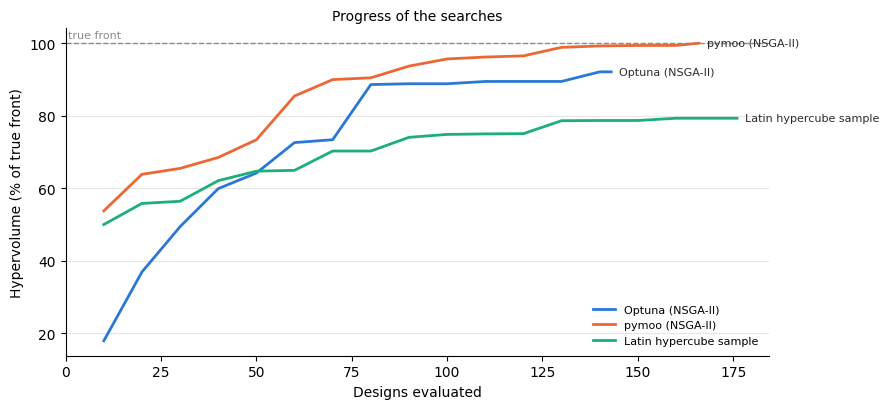

In [4]:
import matplotlib.pyplot as plt

from tatc.tradespace import plot_progress
from tatc.tradespace.plotting import GRAY

ax = plot_progress(progress)
ax.axhline(100, color=GRAY, lw=1, ls="--")
ax.annotate("true front", (0, 100), xytext=(2, 4), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(ylabel="Hypervolume (% of true front)")
ax.set_title("Progress of the searches", fontsize=10)
ax.figure.tight_layout()
plt.show()

Both optimizers find more of the front than a sample of as many designs. pymoo finds the whole front with 166 designs, 15% of the space (its other 34 proposals violate the constraint on the number of satellites). Optuna finds 92% of the hypervolume with 143 designs, and the sample 79% with 176. The searches stop at their budget, not when they converge: a larger budget, or screening first, would bring Optuna's closer to the true front.

## Summary

* The hypervolume measures how close a set of designs comes to the true front (`hypervolume`, and `hypervolume_progress` as a search proceeds).
* `screen` evaluates every design with a cheap study and only the best with the full one, which finds the front at a fraction of the cost if the cheap study ranks designs as the full one does.
* `optimize_optuna` and `optimize_pymoo` search spaces too large to enumerate, and find most of the front with a fraction of the designs.

A search chooses its front from the mean of each design's replicates, which favors designs whose replicates were lucky. The next notebook, `RankUncertainDesigns`, ranks designs with the uncertainty of their replicates, for the results of a search as for those of every design.

## Notes

* How many designs to keep depends on how well the cheap study ranks designs. Check it on a sample of designs evaluated with both studies before screening a large space.
* The results of a search depend on its seed: over eight seeds, pymoo's search here finds 88 to 100% of the hypervolume (96.5% on average). Compare several seeds before relying on one.
* Many encoded points decode to the same design (those in the same level of each variable, or that differ only in the variables of an alternative not chosen). `optimize_pymoo` eliminates proposals of designs proposed or evaluated before, which pymoo's own elimination of equal points does not see.